# Zero-Shot Classification, Report Generation, and Anatomy Localization with MedGemma 1.5
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/f10409/MedGemma_demo/blob/main/1_medgemma_demo.ipynb)

In this notebook, you use MedGemma 1.5 on chest X-rays (CXR) for three tasks:
1. **Classification:** ask a yes/no question, for example "Is there pleural effusion in this image?" This is **zero-shot**: the model gets no examples and no extra training.
2. **Report generation:** the model writes the findings of a report. You compare them with the radiologist's findings.
3. **Anatomy localization:** the model gives a box around a body part, for example the right lung.

Links: [Model card](https://huggingface.co/google/medgemma-1.5-4b-it) · [Developer site](https://developers.google.com/health-ai-developer-foundations/medgemma) · [MedGemma paper](https://arxiv.org/abs/2507.05201) · [MedGemma 1.5 paper](https://arxiv.org/abs/2604.05081)

<img src="https://raw.githubusercontent.com/f10409/MedGemma_demo/main/notebook_figs/medgemma_overview0.png" alt="overview" width="750"> <br>

### What is new in MedGemma 1.5?
- There is only a **4B** model (4 billion parameters).
- It is much better at anatomy localization.

## Colab Setup
1. Select a GPU: **Runtime → Change runtime type → T4 GPU**.
2. Do `0_hugging_face.ipynb` first. It gives you access to MedGemma 1.5.

The next cell downloads the helper code (`utils/`). It also installs [RadHarmony](https://github.com/f10409/RadHarmony), a package that loads the dataset.

In [1]:
import os
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Get the helper code (utils/) from GitHub
    if not os.path.exists("/content/MedGemma_demo"):
        !git clone -q https://github.com/f10409/MedGemma_demo.git /content/MedGemma_demo
    %cd /content/MedGemma_demo

    # RadHarmony loads the dataset. --no-deps keeps the Colab packages unchanged,
    # so we install only the RadHarmony packages that Open-i needs.
    !pip install -q --no-deps git+https://github.com/f10409/RadHarmony.git
    !pip install -q "monai<1.6" pydicom "transformers>=4.56"

In [2]:
import torch

assert torch.cuda.is_available(), "No GPU found. In Colab: Runtime → Change runtime type → T4 GPU."
print(f"GPU: {torch.cuda.get_device_name(0)}")

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


### Hugging Face Login
The next cell reads your token from the `HF_TOKEN` secret. If Colab asks for access, click **Grant access**.

In [3]:
from huggingface_hub import get_token

if get_token() is None:
    raise RuntimeError("No Hugging Face token found. Add the HF_TOKEN secret (see 0_hugging_face.ipynb), "
                       "grant this notebook access, and run this cell again.")
print("✅ Hugging Face token found")

✅ Hugging Face token found


## Import Libraries

In [4]:
# Core libraries
import re
import warnings
import pandas as pd

# ML/AI libraries
import torch
import transformers
from transformers import pipeline
from PIL import Image

# Dataset loading
from radharmony.harmonizer.openi_cxr import OpenICXRHarmonizer
from radharmony.dataset import OpenICXRDataset

# Utilities
from tqdm import tqdm
from utils.binary_metrics import binary_metrics, parse_yes_no, yes_rate_table
from utils.localization import draw_boxes, localization_prompt, pad_to_square, parse_boxes, remove_thinking
from utils.display_prediction import display_prediction
from utils.display_report import display_report
from utils.openi_data import CLASS_NAMES, download_openi, select_cohort, sample_to_example
from utils.preprocess import preprocess
from utils.print_prompt import print_prompt

## Data Preparation
We use the **Open-i chest X-ray dataset** from Indiana University. Everyone can download it for free.
- 7,470 images and 3,955 reports.
- Most reports have a FINDINGS section (what the radiologist sees) and an IMPRESSION section (the conclusion). Private details are replaced with "XXXX".
- Each report has labels, for example "Cardiomegaly" or "No Finding".
- Source: https://openi.nlm.nih.gov/faq. Citation: Demner-Fushman D, et al. *JAMIA* 2016;23(2):304–310.

RadHarmony loads the data in two steps:
1. The **harmonizer** makes one table, with one row for each image.
2. The **dataset** gives one sample at a time: the image, its labels, and its report.

### Download Open-i
This downloads about 1.4 GB and takes a few minutes. If the files are already there, it skips the download.

In [5]:
DATA_DIR = download_openi("data/OpenI-IU-CXR")

✅ Open-i data ready: data/OpenI-IU-CXR


### Harmonize with RadHarmony
`OpenICXRHarmonizer` reads the reports and makes the table. Each row is one image, with its view (frontal or lateral), report, and labels (1 = yes, 0 = no).

In [6]:
harmonizer = OpenICXRHarmonizer(base_dir=DATA_DIR)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # We did not download the DICOM files (75 GB), so DICOM warnings are expected
    df_all = harmonizer.harmonize()

print(f"Harmonized table: {df_all.shape[0]} images, {df_all.shape[1]} columns")
df_all[["patient_id", "image_path", "view_position", "report", *CLASS_NAMES]].head()

Harmonized table: 7470 images, 18 columns


,patient_id,image_path,view_position,report,no_finding,atelectasis,cardiomegaly,consolidation,pleural_effusion
0,CXR1,images/CXR1_1_IM-0001-3001.png,FRONTAL,The cardiac silhouette and mediastinum size ar...,1.0,0.0,0.0,0.0,0.0
1,CXR1,images/CXR1_1_IM-0001-4001.png,LATERAL,The cardiac silhouette and mediastinum size ar...,1.0,0.0,0.0,0.0,0.0
2,CXR2,images/CXR2_IM-0652-1001.png,FRONTAL,Borderline cardiomegaly. Midline sternotomy XX...,0.0,0.0,1.0,0.0,0.0
3,CXR2,images/CXR2_IM-0652-2001.png,LATERAL,Borderline cardiomegaly. Midline sternotomy XX...,0.0,0.0,1.0,0.0,0.0
4,CXR3,images/CXR3_IM-1384-1001.png,FRONTAL,"No displaced rib fractures, pneumothorax, or p...",1.0,0.0,0.0,0.0,0.0


### Select a Balanced Sample
We use only some of the images, to keep the run time short. `select_cohort`:
- keeps frontal images that have a report and exactly one label: No Finding, Atelectasis, Cardiomegaly, Consolidation, or Pleural Effusion
- keeps one image per patient
- takes 20 random images for each label (100 images in total)

We call these 5 labels the **classes**.

In [7]:
meta = select_cohort(df_all, n_per_class=20, seed=5656)
meta.Pathology.value_counts()

Pathology
No Finding          20
Atelectasis         20
Cardiomegaly        20
Consolidation       20
Pleural Effusion    20
Name: count, dtype: int64

To use more images, increase `n_per_class`. Pleural Effusion has only 33 images that we can use.

### Load Samples with the RadHarmony Dataset
`OpenICXRDataset` gives each sample as a Python dict (keys and values): `img` (the image), `cls` (the labels), and `report` (the text).

A `transform` is a function that can change each sample. Our `transform` changes nothing, so `img` stays a file path. We open the image later, when we make the prompt.

In [8]:
def keep_path(sample):
    """Return the sample unchanged, so "img" stays an image file path."""
    return sample


def load_examples(df):
    """Load cohort rows with a RadHarmony dataset. Return the raw samples and the prompt dicts."""
    ds = OpenICXRDataset(
        base_image_dir=DATA_DIR,
        harmonized_df=df,
        transform=keep_path,
        output_cls=True,
        output_report=True,
        cache_dir=None,
    )
    samples = ds.get_datasets()
    examples = [sample_to_example(s, ds.LABEL_COLS) for s in samples]

    # The RadHarmony sample has the full report only. Add the findings and the indication from the table.
    info = df.set_index("image_path")[["findings", "indication"]]
    for s, ex in zip(samples, examples):
        row = info.loc[os.path.relpath(s["img"], DATA_DIR)]
        ex["Findings"] = row["findings"] if pd.notna(row["findings"]) else None
        ex["Indication"] = row["indication"] if pd.notna(row["indication"]) else None
    return samples, examples


samples_eval, examples_eval = load_examples(meta)
print(f"Images in the sample: {len(examples_eval)}")

print("\nRaw RadHarmony sample:")
print(samples_eval[0])
print("\nConverted example (used in the prompts):")
print(examples_eval[0])

Images in the sample: 100

Raw RadHarmony sample:
{'img': 'data/OpenI-IU-CXR/images/CXR1851_IM-0553-1001.png', 'cls': [0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0], 'report': 'Heart size is normal. No focal airspace consolidations. No pneumothorax or effusion. No acute osseous findings. No acute cardiopulmonary findings. .'}

Converted example (used in the prompts):
{'ImagePath': 'data/OpenI-IU-CXR/images/CXR1851_IM-0553-1001.png', 'Pathology': 'No Finding', 'Report': 'Heart size is normal. No focal airspace consolidations. No pneumothorax or effusion. No acute osseous findings. No acute cardiopulmonary findings. .', 'Findings': 'Heart size is normal. No focal airspace consolidations. No pneumothorax or effusion. No acute osseous findings.', 'Indication': 'XXXX-year-old male with XXXX and dyspnea.'}


## Load MedGemma 1.5
We load the model with the Hugging Face `pipeline`.

**Use `bfloat16`, not `float16`.** These are two 16-bit number formats. They use half the memory of 32-bit numbers. With `float16`, the model gave empty answers in our test. `bfloat16` is slower on a T4 GPU, but it works.

In [9]:
# Load the MedGemma 1.5 model
model_id = "google/medgemma-1.5-4b-it"
print("🔄 Loading MedGemma 1.5 model...")

transformers.logging.set_verbosity_error()  # Hide repeated generation warnings

# Simple API: https://huggingface.co/docs/transformers/en/main_classes/pipelines
try:
    pipe = pipeline(
        "image-text-to-text",
        model=model_id,
        dtype=torch.bfloat16,
        device="cuda",
    )

    # Configure for deterministic output (greedy decoding)
    pipe.model.generation_config.do_sample = False
    print("✅ MedGemma 1.5 model loaded successfully!")

except Exception as e:
    print(f"❌ Error loading model: {str(e)}")
    print("💡 Check that you accepted the model terms on Hugging Face and that a GPU is selected.")
    raise

🔄 Loading MedGemma 1.5 model...


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

✅ MedGemma 1.5 model loaded successfully!


## Zero-Shot Prompting
"Zero-shot" means that we give the model only the task. We give it no examples and no extra training.
- **Good:** simple and fast, with no training.
- **Bad:** the answer format can change, and the results depend on what the model learned before.

#### Structured vs. Unstructured Prompts
An **unstructured prompt** is plain text, like a chat message:
```
"Show me the patient's X-ray from last year and their most recent one, and tell me what's changed."
```

A **structured prompt** is a list of messages. Each message has a role:
```json
[
  {
    "role": "system",
    "content": "You are an expert radiologist."
  },
  {
    "role": "user",
    "content": [
      {"type": "image", "image": "..."},
      {"type": "text", "text": "Is there pleural effusion in this image? ..."}
    ]
  }
]
```
- **System prompt:** tells the model its role, for example "You are an expert radiologist." It applies to the full conversation.
- **User prompt:** the task and the input (text and images).

A structured prompt makes the roles clear, and it is easy to add images.

### The MedGemma Evaluation Protocol
We use the same method as the MedGemma papers ([MedGemma](https://arxiv.org/abs/2507.05201), Table A7; [MedGemma 1.5](https://arxiv.org/abs/2604.05081), Table 8):
- **One yes/no question for each condition:** "Is there {condition} in this image?"
- **A fixed answer format:** after the question, we add `You MUST end your response with either "Final Answer: yes" or "Final Answer: no"`. Then code can read the answer easily.
- **Image first,** then the text.
- **Greedy decoding:** the model always picks the most likely next token (a word or a part of a word). So you get the same answer each time.
- **Score: F1** for each condition, and the **macro F1** (the mean of the F1 scores). F1 is from 0 to 1, and higher is better. F1 is high only if the model finds most true cases and most of its "yes" answers are correct.

We ask about 4 conditions: Atelectasis, Cardiomegaly, Consolidation, and Pleural Effusion. So each image gets 4 questions (100 images × 4 = 400 questions).

Example: for a Cardiomegaly image, the correct answers are "yes" for Cardiomegaly and "no" for the other 3. For a No Finding image, all 4 answers are "no".

**Differences from the papers:**
- We add the system prompt "You are an expert radiologist.", as Google's [quick-start notebook](https://github.com/Google-Health/medgemma/blob/main/notebooks/quick_start_with_hugging_face.ipynb) does. The papers use no system prompt.
- The papers use 5 conditions and other datasets (MIMIC-CXR and CheXpert). So you cannot compare our F1 with the papers.

In [10]:
# System prompt for all tasks in this notebook
SYSTEM_MESSAGE = {"role": "system", "content": [{"type": "text", "text": "You are an expert radiologist."}]}

# Class name -> condition name in the question
CONDITIONS = {
    "Atelectasis": "atelectasis",
    "Cardiomegaly": "cardiomegaly",
    "Consolidation": "consolidation",
    "Pleural Effusion": "pleural effusion",
}

# Answer format from the MedGemma 1.5 report (Table 8)
ANSWER_FORMAT = 'You MUST end your response with either "Final Answer: yes" or "Final Answer: no"'


class ZeroShotPrompt:
    """Zero-shot yes/no prompting for one condition in a CXR"""

    def format_prompt(self, condition, prompt=None):
        """Create the question for one condition"""
        if prompt is not None:
            return prompt
        return f"Is there {CONDITIONS[condition]} in this image? {ANSWER_FORMAT}"

    def format_data(self, example, condition, prompt=None):
        """Format one example and one condition for the model"""
        return [
            SYSTEM_MESSAGE,
            {
                "role": "user",
                "content": [
                    {"type": "image", "image": preprocess(Image.open(example['ImagePath']))},
                    {"type": "text", "text": self.format_prompt(condition, prompt)},
                ],
            },
        ]

### Zero-Shot Prompt Example
Let's look at the prompt for one image and one condition.

CONVERSATION PROMPT

[SYSTEM]
----------------------------------------
You are an expert radiologist.

[USER]
----------------------------------------
  📷 PIL Image - Mode: RGB, Size: 512x420


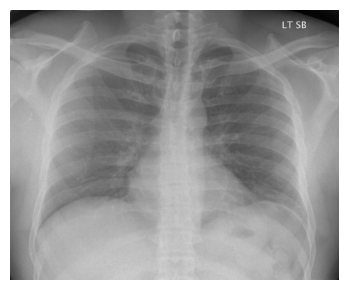

Is there atelectasis in this image? You MUST end your response with either "Final Answer: yes" or "Final Answer: no"



In [11]:
zeroshot = ZeroShotPrompt()

# Select an example, and ask about its own class (or Cardiomegaly for a No Finding image)
example = examples_eval[56]
condition = example["Pathology"] if example["Pathology"] in CONDITIONS else "Cardiomegaly"

messages = zeroshot.format_data(example, condition)
print_prompt(messages)

### Zero-Shot Prediction
Let's run the model on this prompt.

🔄 Running zero-shot prediction...


Question: Is there atelectasis?
Model response: Final Answer: yes
True pathology: Atelectasis


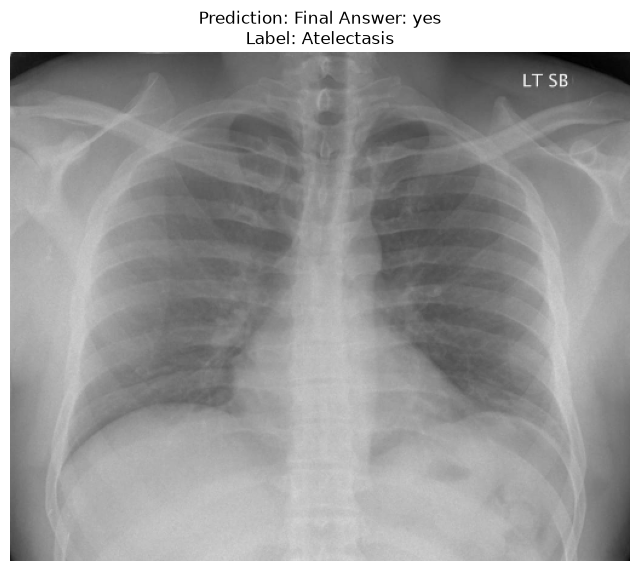

In [12]:
print("🔄 Running zero-shot prediction...")

output = pipe(
    text=messages,          # Structured prompt with system + user messages
    max_new_tokens=200,     # The model may write a short argument before the final answer
    return_full_text=False, # Return only generated text, not input prompt
)

print(f"Question: Is there {CONDITIONS[condition]}?")
print(f"Model response: {output[0]['generated_text'].strip()}")
print(f"True pathology: {example['Pathology']}")

# Display the prediction with image
display_prediction(output, example, figsize=(8, 8))

### Try your own prompt and other examples
Change the prompt and run it again. For example, ask the question in other words, ask about another condition, or remove the answer format.

CONVERSATION PROMPT

[SYSTEM]
----------------------------------------
You are an expert radiologist.

[USER]
----------------------------------------
  📷 PIL Image - Mode: RGB, Size: 512x512


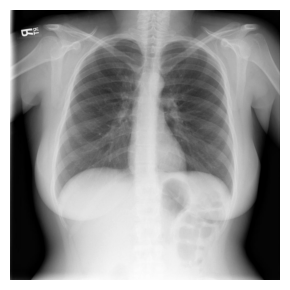

Is the heart enlarged in this chest X-ray? Answer yes or no.



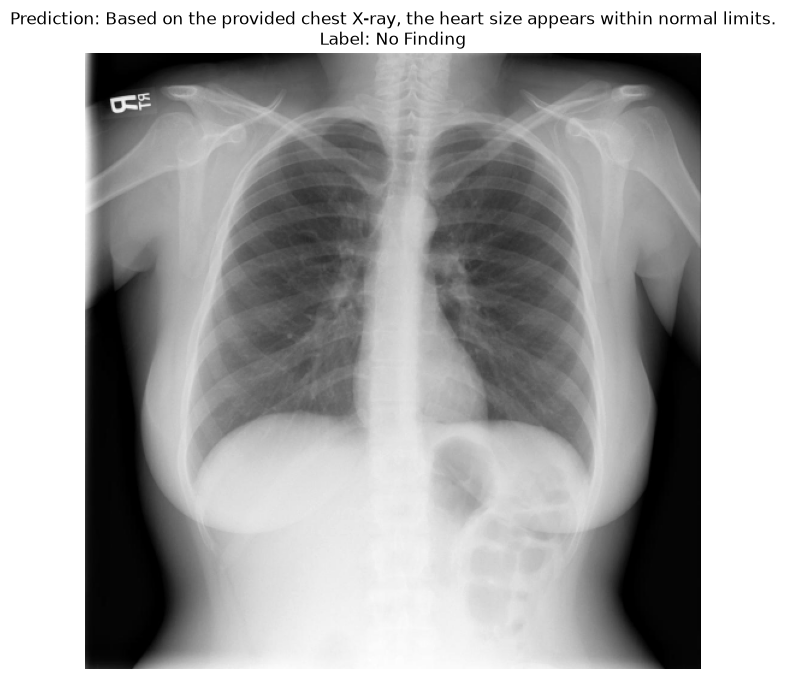

In [13]:
prompt = "Is the heart enlarged in this chest X-ray? Answer yes or no."

example = examples_eval[10]  # you can select other sample
messages = zeroshot.format_data(example, "Cardiomegaly", prompt)
print_prompt(messages)

output = pipe(text=messages, max_new_tokens=200, return_full_text=False)
display_prediction(output, example, figsize=(8, 8))

### Batch Zero-Shot Evaluation
Now we ask all 4 questions for each of the 100 images (400 questions). This is slow on a T4. To make it faster, use a smaller `n_per_class`.

#### Read the Answers
`parse_yes_no` finds the last "Final Answer: yes" or "Final Answer: no" in the answer. If it finds neither, it gives "invalid".

Example: "The costophrenic angles are blunted. Final Answer: yes" gives "yes".

In [14]:
def run_yes_no(prompter, examples, chunk_size=20, max_new_tokens=200):
    """
    Ask every condition for every example.

    Args:
        prompter: ZeroShotPrompt.
        examples: List of example dicts.
        chunk_size: Prompts per progress-bar step. The pipeline still runs one prompt at a time.

    Returns:
        DataFrame: One row per (image, condition) with the label, prediction, and response.
    """
    rows = [(ex, cond) for ex in examples for cond in CONDITIONS]
    responses = []
    for i in tqdm(range(0, len(rows), chunk_size), desc="Progress"):
        batch = rows[i:i + chunk_size]
        outputs = pipe(
            text=[prompter.format_data(ex, cond) for ex, cond in batch],
            max_new_tokens=max_new_tokens,
            return_full_text=False,
        )
        responses += [out[0]["generated_text"] for out in outputs]

    return pd.DataFrame({
        "ImagePath": [ex["ImagePath"] for ex, _ in rows],
        "Pathology": [ex["Pathology"] for ex, _ in rows],
        "Condition": [cond for _, cond in rows],
        "Label": ["yes" if ex["Pathology"] == cond else "no" for ex, cond in rows],
        "Prediction": [parse_yes_no(r) for r in responses],
        "Response": responses,
    })

#### Run Inference

In [15]:
print(f"🔄 Evaluating zero-shot prompting on {len(examples_eval)} images x {len(CONDITIONS)} conditions...")
results_zeroshot = run_yes_no(zeroshot, examples_eval)

metrics_zeroshot = binary_metrics(results_zeroshot)
print("\n📊 Zero-Shot Results:")
print("=" * 30)
print(f"Macro F1: {metrics_zeroshot.loc['Macro average', 'F1']:.3f}")
print(f"Invalid answers: {(results_zeroshot['Prediction'] == 'invalid').sum()}/{len(results_zeroshot)}")
metrics_zeroshot.round(2)

🔄 Evaluating zero-shot prompting on 100 images x 4 conditions...


Progress:   0%|          | 0/20 [00:00<?, ?it/s]

Progress:   5%|▌         | 1/20 [00:03<01:05,  3.45s/it]

Progress:  10%|█         | 2/20 [00:06<01:00,  3.34s/it]

Progress:  15%|█▌        | 3/20 [00:10<00:56,  3.32s/it]

Progress:  20%|██        | 4/20 [00:13<00:52,  3.29s/it]

... (15 outputs left out)

Progress: 100%|██████████| 20/20 [01:06<00:00,  3.32s/it]

Progress: 100%|██████████| 20/20 [01:06<00:00,  3.31s/it]


📊 Zero-Shot Results:
Macro F1: 0.554
Invalid answers: 0/400


,Positives,TP,FN,FP,TN,Invalid,Sensitivity,Specificity,F1
Atelectasis,20,14,6,37,43,0,0.70,0.54,0.39
Cardiomegaly,20,16,4,12,68,0,0.80,0.85,0.67
Consolidation,20,6,14,1,79,0,0.30,0.99,0.44
Pleural Effusion,20,11,9,0,80,0,0.55,1.00,0.71
Macro average,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0.59,0.84,0.55


#### Error Analysis
This **yes-rate table** shows how often the model says **yes**. The rows are the true classes, and the columns are the questions.
- Where the row and the column are the same class, the value should be high. This is the sensitivity: how often the model finds the condition.
- All other values should be low. A high value shows false positives: the model says "yes", but the condition is not there.

Example: a high value in row "Pleural Effusion", column "Atelectasis" means that the model often says "yes" to atelectasis for effusion images. This is not a surprise, because the two often occur together.

In [16]:
yes_rate_table(results_zeroshot).round(2)

Condition,Atelectasis,Cardiomegaly,Consolidation,Pleural Effusion
Pathology,,,,
No Finding,0.05,0.20,0.00,0.00
Atelectasis,0.70,0.10,0.00,0.00
Cardiomegaly,0.30,0.80,0.00,0.00
Consolidation,0.60,0.15,0.30,0.00
Pleural Effusion,0.90,0.15,0.05,0.55


In [17]:
# Look at a few wrong answers
wrong = results_zeroshot[results_zeroshot["Prediction"] != results_zeroshot["Label"]]
wrong[["Pathology", "Condition", "Label", "Prediction", "Response"]].head(10)

,Pathology,Condition,Label,Prediction,Response
29,No Finding,Cardiomegaly,no,yes,Final Answer: yes
32,No Finding,Atelectasis,no,yes,Final Answer: yes
37,No Finding,Cardiomegaly,no,yes,Final Answer: yes
48,Cardiomegaly,Atelectasis,no,yes,Final Answer: yes
65,No Finding,Cardiomegaly,no,yes,Final Answer: yes
69,No Finding,Cardiomegaly,no,yes,Final Answer: yes
80,Atelectasis,Atelectasis,yes,no,Final Answer: no
100,Atelectasis,Atelectasis,yes,no,Final Answer: no
105,Atelectasis,Cardiomegaly,no,yes,Final Answer: yes
109,Cardiomegaly,Cardiomegaly,yes,no,Final Answer: no


### Summary
**What we did:**
- ✅ We asked yes/no questions with the prompt from the MedGemma papers.
- ✅ We scored 4 conditions on 100 images (400 questions) with F1.

**Key points:**
- The "Final Answer: yes/no" format makes the answers easy to read with code. Check the number of invalid answers above.
- Zero-shot results are a baseline. You can compare other methods with them.

**Limitations:**
- ❌ We used only 100 images. With another sample, the F1 values can change.

**Questions to think about:**
- Which conditions does the model miss most often?
- Which conditions get too many "yes" answers? Look at the yes-rate table.

**Next:** report generation.

## Report Generation
MedGemma can also **write a radiology report**. Open-i has the radiologist's report for each image, so we can compare the two.

We use the prompt from the [MedGemma paper](https://arxiv.org/abs/2507.05201) (Table A7): the image, then `<INDICATION> findings:`. The **indication** is the reason for the exam, for example "Chest pain." The model then writes the findings.

**Differences from the paper:**
- The paper used the pretrained MedGemma 1 model. This model is not trained to follow instructions. MedGemma 1.5 has only the instruction-tuned model ("-it"), so we use it.
- We keep our system prompt ("You are an expert radiologist."). The paper used none.
- The model often writes an IMPRESSION section too. We keep only the findings.

**How good are the reports?** The model card gives a RadGraph F1 of 27.2 (a score that compares the clinical findings in two reports). It needs extra packages, so we do not compute it here. The bonus section at the end has a simpler check.

> ⚠️ Generated reports are for research and education only. Do not use them for patient care.

### Report Prompt
Open-i replaces private details with "XXXX". So some indications look like "XXXX-year-old male with chest pain." If there is no indication, the prompt is only "findings:".

In [18]:
def format_report_prompt(example, prompt=None):
    """Make the messages to generate findings for one image. Default prompt: "<INDICATION> findings:"."""
    if prompt is None:
        indication = example.get("Indication")
        has_indication = isinstance(indication, str) and indication.strip()
        prompt = f"{indication} findings:" if has_indication else "findings:"
    return [
        SYSTEM_MESSAGE,
        {
            "role": "user",
            "content": [
                {"type": "image", "image": preprocess(Image.open(example["ImagePath"]))},
                {"type": "text", "text": prompt},
            ],
        },
    ]


def extract_findings(text):
    """Keep only the findings part of a generated report (remove the FINDINGS title and the IMPRESSION section)."""
    m = re.search(r"\bfindings\b[\s*#]*:", text, flags=re.IGNORECASE)  # The title needs a colon
    if m:
        text = text[m.end():]
    text = re.split(r"[\s*#]*\bimpression\b[\s*#]*:", text, flags=re.IGNORECASE)[0]
    return re.sub(r"^\s*(\*\*\s*)?", "", text).rstrip(" \n*#")


def generate_report(example, prompt=None, max_new_tokens=300):
    """Generate a report for one image. Return the full generated text."""
    output = pipe(
        text=format_report_prompt(example, prompt),
        max_new_tokens=max_new_tokens,   # Reports are longer than yes/no answers
        return_full_text=False,
    )
    return output[0]["generated_text"].strip()

### Report Generation Example

CONVERSATION PROMPT

[SYSTEM]
----------------------------------------
You are an expert radiologist.

[USER]
----------------------------------------
  📷 PIL Image - Mode: RGB, Size: 512x420
XXXX-year-old male with chest pain findings:

🔄 Generating report...


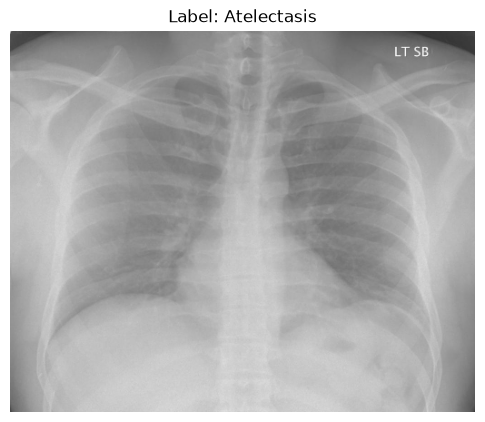

📋 INDICATION: XXXX-year-old male with chest pain

🤖 GENERATED (MedGemma)
------------------------------------------------------------
The lungs are clear without focal consolidation, pleural effusion, or pneumothorax. The
cardiomediastinal silhouette is normal. The osseous structures are unremarkable.

📝 TRUE (radiologist)
------------------------------------------------------------
Low lung volumes. Cardiac and mediastinal contours are unremarkable. Pulmonary vascularity is within
normal limits. No focal air space opacities, pleural effusion, or pneumothorax. Mild left lingular
platelike atelectasis. XXXX are grossly unremarkable.


In [19]:
example = examples_eval[56]
print_prompt(format_report_prompt(example), show_images=False)

print("🔄 Generating report...")
report = generate_report(example)

display_report(example, extract_findings(report), example["Findings"])

### Try your own report prompt
Ideas:
- Remove the indication. Use only "findings:".
- Ask for a full report: "Write a radiology report for this chest X-ray. Use two sections: FINDINGS and IMPRESSION."
- Ask the model to describe the heart, lungs, pleura, and bones one at a time.

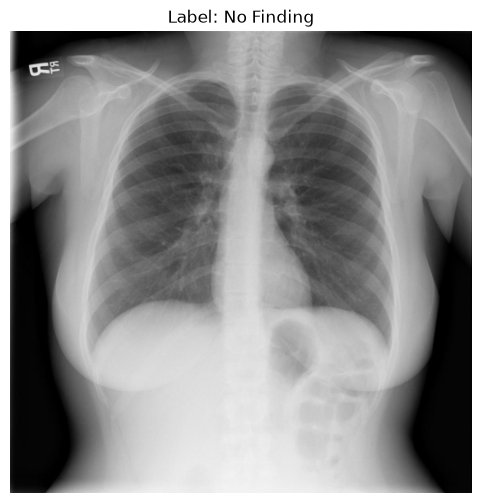

📋 INDICATION: XXXX-year-old woman with XXXX.

🤖 GENERATED (MedGemma)
------------------------------------------------------------
FINDINGS:
The heart size is normal. The mediastinal and hilar contours are normal. The lungs are clear without
focal consolidation, pleural effusion, or pneumothorax. The visualized osseous structures are
unremarkable. IMPRESSION:
Normal chest X-ray.

📝 TRUE (radiologist)
------------------------------------------------------------
Heart size, mediastinal contour, and pulmonary vascularity are within normal limits. No focal
consolidation, pleural effusion, or pneumothorax is identified. No acute osseous abnormality
identified. No acute cardiopulmonary abnormality. .


In [20]:
my_prompt = "Write a radiology report for this chest X-ray. Use two sections: FINDINGS and IMPRESSION."

example = examples_eval[10]  # you can select other sample
report = generate_report(example, prompt=my_prompt)
display_report(example, report, example["Report"])

### Summary
**What we did:**
- ✅ MedGemma wrote the findings for one image, with the "<INDICATION> findings:" prompt from the paper. We compared them with the radiologist's findings.
- ✅ You tried your own prompt on a second image.

**Key points:**
- A report can read well and still be wrong. For example, it can miss a finding.
- Look for **normal bias**: does the model write "the lungs are clear" for an abnormal image?

**Limitations:**
- ❌ We looked at only 2 images. A real test needs more images and a clinical score, such as RadGraph F1.
- ❌ The model sees only one frontal image and the indication. It has no lateral view and no prior exam.

**Next:** anatomy localization.

## Anatomy Localization
MedGemma 1.5 can also **find a body part** in a chest X-ray. It gives a **bounding box** (a rectangle) around it, and our code draws the box. This is new in 1.5. On the model card, the box overlap score (IoU, 0–100) went from 3.1 (MedGemma 1) to 38.0 (MedGemma 1.5).

We use the steps from Google's [anatomy localization notebook](https://github.com/Google-Health/medgemma/blob/main/notebooks/cxr_anatomy_localization_with_hugging_face.ipynb):
- **Prompt:** asks "Where is the {object}?" and explains the box format. A box is `[y0, x0, y1, x1]` (y comes first), with values from 0 to 1000. The prompt also says that "left" means the patient's left.
- **Image:** we add black borders to make it square. The box values are for this square image.
- **Thinking:** the model first writes its thinking (the text between `<unused94>` and `<unused95>`). Then it gives the answer. We remove the thinking and keep the answer.

**Differences from Google's notebook:** we keep our system prompt. Before we make the image square, we change it to an 8-bit RGB image with our `preprocess` function.

Open-i has no true boxes, so we cannot compute IoU. We check the boxes by eye and with a left/right check.

> ⏱️ Each object takes a long time, because the model first writes about 500 tokens of thinking. On our GPU (RTX PRO 6000), this took about 12 s per object. A T4 is several times slower.

In [21]:
def localize(image, object_name, max_new_tokens=1000):
    """Ask MedGemma for the box of one object. Return (boxes, answer text without the thinking trace)."""
    messages = [
        SYSTEM_MESSAGE,
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": localization_prompt(object_name)},
            ],
        },
    ]
    output = pipe(text=messages, max_new_tokens=max_new_tokens, return_full_text=False)
    response = output[0]["generated_text"]
    return parse_boxes(response), remove_thinking(response)


example = examples_eval[56]
image = pad_to_square(preprocess(Image.open(example["ImagePath"])))
print(localization_prompt("right clavicle"))

Instructions:
The following user query will require outputting bounding boxes. The format of bounding boxes coordinates is [y0, x0, y1, x1] where (y0, x0) must be top-left corner and (y1, x1) the bottom-right corner. This implies that x0 < x1 and y0 < y1. Always normalize the x and y coordinates the range [0, 1000], meaning that a bounding box starting at 15% of the image width would be associated with an x coordinate of 150. You MUST output a single parseable json list of objects enclosed into ```json...``` brackets, for instance ```json[{"box_2d": [800, 3, 840, 471], "label": "car"}, {"box_2d": [400, 22, 600, 73], "label": "dog"}]``` is a valid output. Now answer to the user query.

Remember "left" refers to the patient's left side where the heart is and sometimes underneath an L in the upper right corner of the image.

Query:
Where is the right clavicle? Don't give a final answer without reasoning. Output the final answer in the format "Final Answer: X" where X is a JSON list of obj

### Localization Example
We ask for 4 body parts in one image. We keep the first box for each one. We print the full answer only for the last one.

Objects:   0%|          | 0/4 [00:00<?, ?it/s]

Objects:  25%|██▌       | 1/4 [00:13<00:40, 13.45s/it]

Objects:  50%|█████     | 2/4 [00:26<00:26, 13.00s/it]

Objects:  75%|███████▌  | 3/4 [00:38<00:12, 12.68s/it]

Objects: 100%|██████████| 4/4 [00:51<00:00, 12.84s/it]

Objects: 100%|██████████| 4/4 [00:51<00:00, 12.88s/it]

Answer for 'right clavicle':
Final Answer: ```json[{"box_2d": [125, 155, 310, 460], "label": "right clavicle"}]```



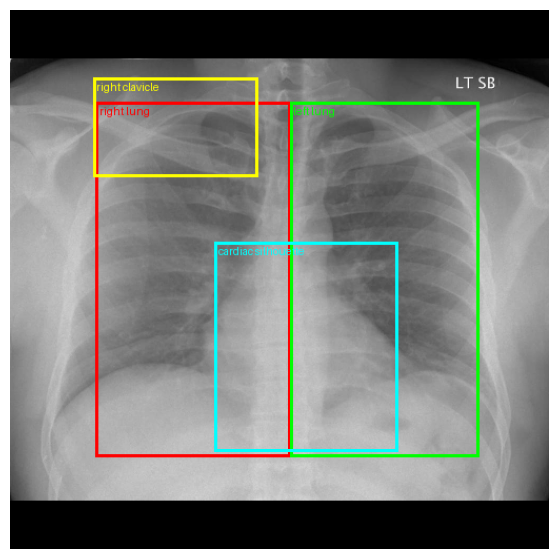

In [22]:
objects = ["right lung", "left lung", "cardiac silhouette", "right clavicle"]

all_boxes = []
for name in tqdm(objects, desc="Objects"):
    boxes, answer = localize(image, name)
    all_boxes += [{"box_2d": b["box_2d"], "label": name} for b in boxes[:1]]  # Keep the first box for each object

print(f"Answer for '{objects[-1]}':\n{answer}\n")
draw_boxes(image, all_boxes)

### Left/Right Check
On a frontal X-ray, the patient's right side is on the left side of the image. So the "right lung" box should be to the left of the "left lung" box: its center x value should be **smaller**.

In [23]:
centers = {b["label"]: (b["box_2d"][1] + b["box_2d"][3]) / 2 for b in all_boxes}

if "right lung" in centers and "left lung" in centers:
    print(f"Right lung box center x: {centers['right lung']:.0f}")
    print(f"Left lung box center x:  {centers['left lung']:.0f}")
    print("✅ Correct side" if centers["right lung"] < centers["left lung"] else "❌ Wrong side")
else:
    print("A lung box is missing. Look at the answers above.")

Right lung box center x: 340
Left lung box center x:  695
✅ Correct side


### Try your own object
Ideas: "trachea", "aortic arch", "left costophrenic angle", "right hilar structures", "left clavicle".

Final Answer: ```json[{"box_2d": [160, 420, 410, 530], "label": "trachea"}]```


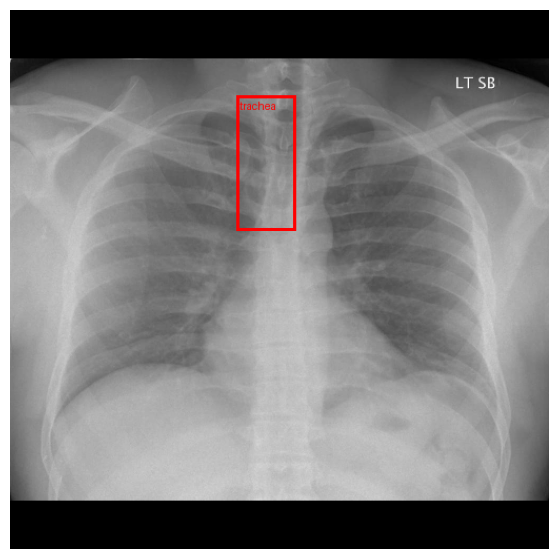

In [24]:
my_object = "trachea"

boxes, answer = localize(image, my_object)
print(answer)
draw_boxes(image, [{"box_2d": b["box_2d"], "label": my_object} for b in boxes])

### Summary
**What we did:**
- ✅ MedGemma 1.5 found body parts, with the prompt from Google's notebook.
- ✅ We drew the boxes and checked the left and right sides.

**Key points:**
- MedGemma 1 gave almost no useful boxes. MedGemma 1.5 is much better, but its boxes are often too large or too small.
- Check the boxes by eye. A box can be on the correct side and still have the wrong size. For example, look at the "right clavicle" box.

**Limitations:**
- ❌ Open-i has no true boxes, so we cannot compute IoU.
- ❌ The model writes long thinking text for each object, so it is slow.

**Next:** the bonus section.

## Bonus: Batch Report Generation and Label Check
Here we test the reports on more images, with a simple **label check**:
1. MedGemma writes findings for `N_PER_CLASS` images per class (2 per class = 10 images). We use only images whose true report has a findings section.
2. MedGemma reads its **generated** findings (text only, no image) and picks one class.
3. MedGemma does the same with the **true** findings.

If the generated findings are correct, the class from them should match the label.
Example: the label is "Cardiomegaly", and the generated findings say "The heart is enlarged". The label check should give "Cardiomegaly".

Step 3 can also give the wrong class. Then the label check made a mistake, or the label and the report do not agree.

Note: for some text-only questions, MedGemma writes its thinking (`<unused94>` ... `<unused95>`) without being asked. We remove it and keep only the answer.

In [25]:
N_PER_CLASS = 2  # Reports per class. Reports are long, so this step is slow on a T4.

# Take the first N_PER_CLASS images of each class that have true findings
report_examples = []
for cls in CLASS_NAMES.values():
    report_examples += [ex for ex in examples_eval if ex["Pathology"] == cls and ex["Findings"]][:N_PER_CLASS]

print(f"🔄 Generating {len(report_examples)} reports...")
generated_findings = [extract_findings(generate_report(ex)) for ex in tqdm(report_examples)]

🔄 Generating 10 reports...


  0%|          | 0/10 [00:00<?, ?it/s]

 10%|█         | 1/10 [00:01<00:11,  1.28s/it]

 20%|██        | 2/10 [00:02<00:10,  1.28s/it]

 30%|███       | 3/10 [00:04<00:11,  1.62s/it]

 40%|████      | 4/10 [00:05<00:08,  1.44s/it]

... (3 outputs left out)

 80%|████████  | 8/10 [00:12<00:03,  1.51s/it]

 90%|█████████ | 9/10 [00:13<00:01,  1.29s/it]

100%|██████████| 10/10 [00:14<00:00,  1.29s/it]

100%|██████████| 10/10 [00:14<00:00,  1.44s/it]

In [26]:
CLASSES = list(CLASS_NAMES.values())


def postprocess_prediction(text, classes):
    """
    Find the class name that comes first in a free-text response.

    Args:
        text: Model response.
        classes: List of valid class names.

    Returns:
        str: Class name that appears first in the response, or "Invalid" if no class is found.
    """
    text = text.lower()
    positions = {label: text.find(label.lower()) for label in classes}
    found = {label: pos for label, pos in positions.items() if pos >= 0}
    return min(found, key=found.get) if found else "Invalid"


def format_label_check(findings):
    """Make text-only messages that ask the model to select one class from the findings."""
    options = "\n".join(CLASSES)
    text = (
        f"Here are the findings of a chest X-ray report:\n\n{findings}\n\n"
        f"Which option best matches the findings?\n\nOptions:\n{options}\n\n"
        "If the findings have none of these conditions, answer 'No Finding'. "
        "Respond with only one option from the list."
    )
    return [SYSTEM_MESSAGE, {"role": "user", "content": [{"type": "text", "text": text}]}]


def findings_to_label(findings):
    """Ask MedGemma for one class from the findings. Return (class or "Invalid", answer text)."""
    # MedGemma 1.5 sometimes starts a thinking trace (<unused94>thought ... <unused95>), so allow more tokens
    output = pipe(text=format_label_check(findings), max_new_tokens=1000, return_full_text=False)
    response = output[0]["generated_text"].strip()
    if response.startswith("<unused94>"):
        if "<unused95>" not in response:
            return "Invalid", response  # The thinking did not finish
        response = response.split("<unused95>")[-1].strip()  # Keep only the answer after the thinking
    return postprocess_prediction(response, CLASSES), response


checks_generated = [findings_to_label(f) for f in tqdm(generated_findings, desc="Generated findings")]
checks_true = [findings_to_label(ex["Findings"]) for ex in tqdm(report_examples, desc="True findings")]

report_results = pd.DataFrame({
    "Label": [ex["Pathology"] for ex in report_examples],
    "From generated findings": [label for label, _ in checks_generated],
    "From true findings": [label for label, _ in checks_true],
    "Answer (true findings)": [raw for _, raw in checks_true],
})

print("📊 Label Check Results:")
print("=" * 30)
print(f"Generated findings match label: {(report_results['From generated findings'] == report_results['Label']).mean():.0%}")
print(f"True findings match label:      {(report_results['From true findings'] == report_results['Label']).mean():.0%}")
report_results

Generated findings:   0%|          | 0/10 [00:00<?, ?it/s]

Generated findings:  20%|██        | 2/10 [00:00<00:00, 12.43it/s]

Generated findings:  20%|██        | 2/10 [00:14<00:00, 12.43it/s]

Generated findings:  30%|███       | 3/10 [00:20<01:00,  8.62s/it]

Generated findings:  50%|█████     | 5/10 [00:20<00:19,  3.98s/it]

Generated findings:  70%|███████   | 7/10 [00:21<00:06,  2.27s/it]

... (8 outputs left out)

True findings: 100%|██████████| 10/10 [00:27<00:00,  2.58s/it]

True findings: 100%|██████████| 10/10 [00:27<00:00,  2.80s/it]

📊 Label Check Results:
Generated findings match label: 40%
True findings match label:      70%


,Label,From generated findings,From true findings,Answer (true findings)
0,No Finding,No Finding,No Finding,No Finding
1,No Finding,No Finding,No Finding,No Finding
2,Atelectasis,Atelectasis,Atelectasis,Atelectasis
3,Atelectasis,No Finding,Atelectasis,Atelectasis
4,Cardiomegaly,No Finding,No Finding,No Finding
5,Cardiomegaly,No Finding,No Finding,No Finding
6,Consolidation,No Finding,Atelectasis,Atelectasis
7,Consolidation,No Finding,Consolidation,Consolidation
8,Pleural Effusion,No Finding,Pleural Effusion,Pleural Effusion
9,Pleural Effusion,Pleural Effusion,Pleural Effusion,Pleural Effusion


### Look at the Reports
Compare the generated and true findings. Look for findings that the model missed or added.

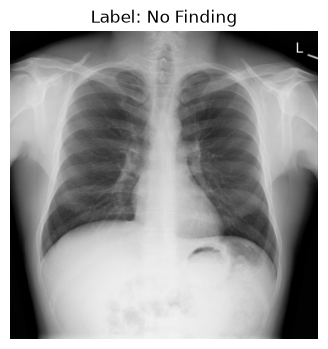

📋 INDICATION: XXXX-year-old male with XXXX and dyspnea.

🤖 GENERATED (MedGemma)
------------------------------------------------------------
The lungs are clear without focal consolidation. No pleural effusion or pneumothorax is seen. The
heart size is normal. The mediastinal and hilar contours are unremarkable. The visualized osseous
structures are intact.

📝 TRUE (radiologist)
------------------------------------------------------------
Heart size is normal. No focal airspace consolidations. No pneumothorax or effusion. No acute
osseous findings.




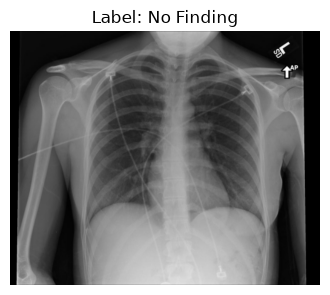

📋 INDICATION: Chest pain, feels out of it.

🤖 GENERATED (MedGemma)
------------------------------------------------------------
The lungs are clear without focal consolidation. No pleural effusion or pneumothorax is seen. The
cardiac silhouette is normal in size. The mediastinal silhouette is unremarkable. The visualized
osseous structures are unremarkable.

📝 TRUE (radiologist)
------------------------------------------------------------
The cardiomediastinal silhouette and pulmonary vasculature are within normal limits in size. The
lungs are clear of focal airspace disease, pneumothorax, or pleural effusion. There are no acute
bony findings.




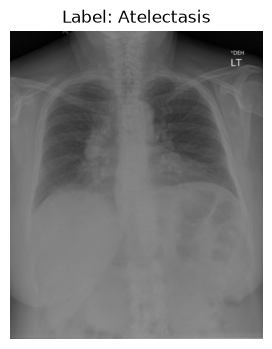

📋 INDICATION: XXXX year-old female with XXXX.

🤖 GENERATED (MedGemma)
------------------------------------------------------------
The lung volumes are low. The heart size is normal. The mediastinal contours are normal. The right
hilum appears enlarged, possibly due to lymphadenopathy or a mass. The left hilum is unremarkable.
There is no pleural effusion or pneumothorax. The visualized osseous structures are unremarkable.

📝 TRUE (radiologist)
------------------------------------------------------------
The heart size is normal. The mediastinal contour is within normal limits. Low lung volumes and
bronchovascular crowding. Mild bibasilar opacities, XXXX atelectasis. The lungs are free of any
focal infiltrates. There are no nodules or masses. No visible pneumothorax. No visible pleural
fluid. Stable degenerative change throughout the thoracic spine. Stable thoracolumbar
retrolisthesis. There is no visible free intraperitoneal air under the diaphragm.




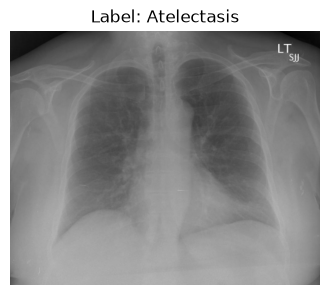

📋 INDICATION: Shortness of breath.

🤖 GENERATED (MedGemma)
------------------------------------------------------------
The lungs are clear without focal consolidation. No pleural effusion or pneumothorax is seen. The
cardiac silhouette is normal in size. The mediastinal and hilar contours are unremarkable.

📝 TRUE (radiologist)
------------------------------------------------------------
Streaky opacity is noted within the left lung base which may represent focal area of atelectasis.
Right lung is grossly clear. Cardiac silhouette and mediastinal contours are within normal limits.
There is no pneumothorax. No large pleural effusion.




In [27]:
for ex, findings in zip(report_examples[:4], generated_findings[:4]):
    display_report(ex, findings, ex["Findings"], figsize=(4, 4))
    print("\n" + "=" * 100 + "\n")

### Bonus Summary
**Key points:**
- **Normal bias:** how many generated findings gave "No Finding"?
- **Is the match rate for the true findings below 100%?** Then the labels and the reports do not agree, or the label check made a mistake. Read the answers to find out which.

**Limitations:**
- ❌ The same model writes and reads the findings. So this is only a rough check.
- ❌ We used only `N_PER_CLASS` images per class. A real test needs more images and a clinical score, such as RadGraph F1.